
# Golden Shiner MAS 
## Complete Working Notebook

This notebook combines the reusable parts of the previous `past_repo` work with the current design:

- 2D fish physics
- Couzin-style **repulsion + orientation + attraction**
- synchronous `decide()` / `advance()` updating
- reflecting walls
- DataCollector V1
- initial state saved at `t = 0`
- simple result inspection
- optional PyVista 3D visualization of the 2D model
- optional light-dependent speed extension for the next phase

## Important design choice

The scientific model is 2D:

\[
p_i = (x_i,y_i)
\]

PyVista only displays it in 3D:

\[
(x_i,y_i)\rightarrow(x_i,y_i,0)
\]

So visualization does **not** change the physics.



## Where each part comes from

| Current part | Previous project source |
|---|---|
| 2D position, direction, movement, wall bounce | `SingleFish_ContinuousSpace.ipynb` |
| Multiple fish + neighbour detection | `Couzin_Parameters.ipynb` |
| Repulsion + attraction functions | `Couzin_Parameters_maria_attraction.ipynb` |
| `decide()` / `advance()` synchronous structure | `Couzin.py` |
| Three Couzin zones and rule priority | `paper_rules.py` |
| Metrics such as polarization / rotation / NND | `model.py` |
| Later group-size / gradient experiments | `paper_experiments.py` |
| DataCollector V1 | new integrated version |

The old files are useful references, but they are alternative development stages.  
The executable model below is the **single integrated version to use now**.


In [1]:

# Optional installation if your environment does not already have these packages:
import numpy as np
import pandas as pd
import mesa

from mesa.datacollection import DataCollector
from mesa.experimental.continuous_space import (
    ContinuousSpaceAgent,
    ContinuousSpace,
)


## Load the shared model

The code for the group metrics, the fish and the model lives in [`shiner_model.py`](shiner_model.py) at the repository root. The checks, the trials and this notebook all import that same file, so the project has **one model**.

The next cell walks up from the current folder until it finds `shiner_model.py`, lets Python import from that folder, and imports the three pieces we need. Sections 1–3 explain what this code does.

In [2]:
from pathlib import Path
import sys

# Find the repository root: start in the current folder and walk up
# until we reach the folder that contains shiner_model.py.
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "shiner_model.py").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("shiner_model.py was not found in this folder or any parent folder.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Let Python import files from the repository root.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import the one shared model: one social decision per step, dt = 0.125 s.
from shiner_model import GoldenShinersModel, GoldenShiners, compute_group_metrics


# 1. Group metrics

These measurements do not affect fish behaviour.  
They only describe what the group is doing.

We record:

- **Polarization** — alignment
- **Rotation** — milling / circular motion
- **MeanSpeed**
- **MeanNND** — mean nearest-neighbour distance
- **MeanDistanceToCentroid** — group compactness
- **CentroidX / CentroidY**
- **CollectiveState**



# 2. Golden Shiner agent

Each fish stores only the state needed for the current model:

\[
(x,y),\quad (d_x,d_y),\quad speed
\]

The social rules use the three Couzin zones:

1. **Repulsion** has priority.
2. If there is no repulsion:
   - orientation,
   - attraction,
   - or their combination.
3. If there are no relevant neighbours, the fish keeps its current direction.


**Note.** The executable classes now live in [`shiner_model.py`](shiner_model.py) (one shared model). Difference from the earlier notebook version: orientation and attraction are added as raw sums before normalising (Puckett et al. SI eq. 7) instead of being normalised separately.


# 3. Model + DataCollector

The model:

1. creates the 2D arena,
2. creates all fish,
3. initializes the DataCollector,
4. saves the initial state at `t = 0`,
5. uses synchronous updates:

```text
decide all
    ↓
advance all
    ↓
record state
```



# 4. Create and run the model

We choose how long to run in **simulated seconds**. 12.5 s is 12.5 / 0.125 = 100 steps.

Because the initial state is collected inside `__init__`, running 12.5 s (100 steps) gives:

- 1 initial state (t = 0 s)
- 100 updated states (t = 0.125 s, 0.25 s, …, 12.5 s)
- 101 recorded group states in total


## Time and decision rate

- One `model.step()` moves the clock forward by `dt = 0.125 s`. In that step **every fish makes one social decision**, then swims in a straight line for 0.125 s.
- So each fish makes **8 decisions per second**, the "Direction update rate" in Puckett et al. (2018), SI Table S1. `dt` is this decision interval: a behavioural parameter, not a numerical step to make smaller.
- Simulated time is `t = model.steps * model.dt`, so 1 s = 8 steps and 12.5 s = 100 steps.
- Why the earlier sub-step version (`dt = 1/64 s`, deciding every 8 steps) was removed: see [chapter 3 of checks/README.md](checks/README.md#chapter-3-the-key-insight-dt-is-the-reaction-time).

In [3]:
# How long to simulate, in seconds (not in steps).
SIMULATED_SECONDS = 12.5

model = GoldenShinersModel(width=20, height=20, n_fish=20, speed=1.0, seed=1)

# One step lasts model.dt = 0.125 s, so 12.5 s needs 100 steps.
for _ in range(round(SIMULATED_SECONDS / model.dt)):
    model.step()

print(f"Ran {model.steps} steps = {model.steps * model.dt} simulated seconds.")

Ran 100 steps = 12.5 simulated seconds.


## Group-level DataCollector output

In [4]:

model_data = (
    model.datacollector
    .get_model_vars_dataframe()
)

# Simulated time of each recorded row: time = step number * dt.
model_data["Time"] = [s * model.dt for s in model.recorded_steps]

model_data.head()


,Polarization,Rotation,MeanSpeed,MeanNND,MeanDistanceToCentroid,CentroidX,CentroidY,CollectiveState,Time
0,0.296489,0.055420,1.0,3.112169,7.821139,9.306132,9.619529,swarm,0.000
1,0.204176,0.010182,1.0,3.018089,7.798115,9.292531,9.597934,swarm,0.125
2,0.158882,0.002917,1.0,2.965809,7.763717,9.276946,9.585624,swarm,0.250
3,0.044727,0.018960,1.0,2.868665,7.719782,9.272999,9.581664,swarm,0.375
4,0.055220,0.049136,1.0,2.806850,7.670806,9.270731,9.575145,swarm,0.500


## Individual-fish DataCollector output

In [5]:

agent_data = (
    model.datacollector
    .get_agent_vars_dataframe()
)

agent_data.head()


X          Y      DirX      DirY  Speed
Step AgentID                                                 
0    1        10.236432  19.009274  0.617071  0.786908    1.0
     2        18.972989   6.236629 -0.886184  0.463334    1.0
     3        16.554052   8.183983 -0.951842 -0.306588    1.0
     4         0.551182  15.070262 -0.971418 -0.237374    1.0
     5         6.594634  15.768574 -0.328045  0.944662    1.0


# 5. Simple checks

These are useful sanity checks before adding light.

We want to verify that:

- directions stay normalized,
- fish stay inside the arena,
- DataCollector actually contains the initial state,
- metrics remain in sensible ranges.


In [6]:

# Check current fish positions and directions

for fish in model.agents:

    assert 0 <= fish.position[0] <= model.bounds[0, 1]
    assert 0 <= fish.position[1] <= model.bounds[1, 1]

    assert np.isclose(
        np.linalg.norm(fish.direction),
        1.0,
    )

print("Basic movement checks passed.")


Basic movement checks passed.


In [7]:

# Check metric ranges

assert model_data["Polarization"].between(0, 1).all()
assert model_data["Rotation"].between(0, 1).all()

print("Metric range checks passed.")


Metric range checks passed.



# 6. Quick plots

These are only for checking whether the schooling dynamics look sensible.


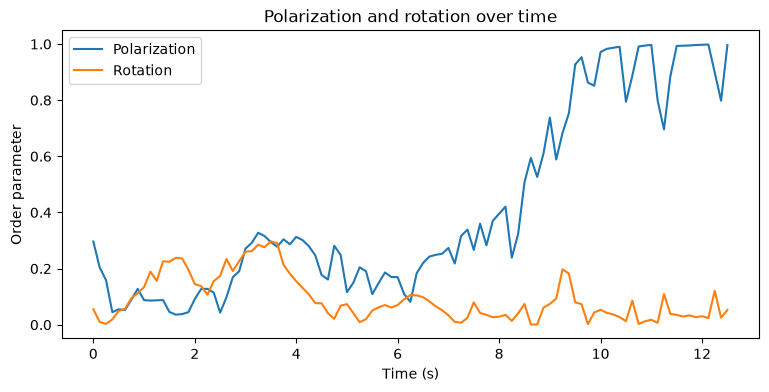

In [8]:

import matplotlib.pyplot as plt

model_data.plot(
    x="Time",
    y=["Polarization", "Rotation"],
    figsize=(9, 4),
)

plt.xlabel("Time (s)")
plt.ylabel("Order parameter")
plt.title("Polarization and rotation over time")
plt.show()


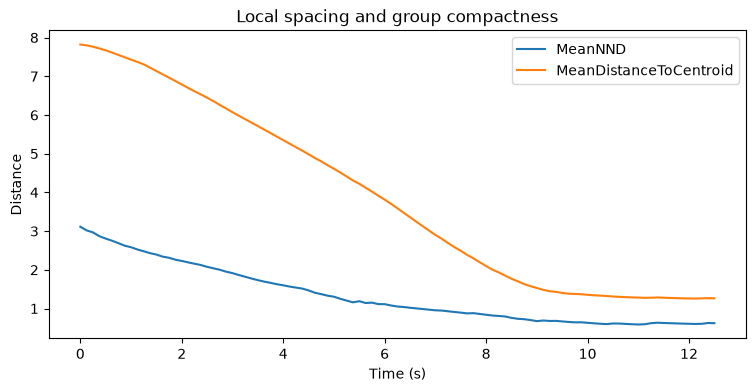

In [9]:

model_data.plot(
    x="Time",
    y=["MeanNND", "MeanDistanceToCentroid"],
    figsize=(9, 4),
)

plt.xlabel("Time (s)")
plt.ylabel("Distance")
plt.title("Local spacing and group compactness")
plt.show()



# 7. PyVista — 3D visualization of the 2D physics

The model remains 2D.

For visualization:

\[
(x,y)\rightarrow(x,y,0)
\]

and

\[
(d_x,d_y)\rightarrow(d_x,d_y,0)
\]

This cell does not alter the simulation.


In [10]:

def get_pyvista_state(model):
    """Convert the current 2D fish state into 3D arrays for visualization."""

    positions_2d = np.array([
        fish.position
        for fish in model.agents
    ])

    directions_2d = np.array([
        fish.direction
        for fish in model.agents
    ])

    # Add z = 0
    positions_3d = np.column_stack([
        positions_2d,
        np.zeros(len(positions_2d)),
    ])

    directions_3d = np.column_stack([
        directions_2d,
        np.zeros(len(directions_2d)),
    ])

    return positions_3d, directions_3d



# 8. Next phase — local light controls speed

Do **not** give the shiner the gradient direction.

The next environmental rule is only:

\[
L_i = L(p_i)
\]

\[
s_i = s_{\min} + L_i(s_{\max}-s_{\min})
\]

So:

- dark region → slower
- bright region → faster

The social rules still determine direction.

This is kept separate from the V1 schooling model so we can first validate the social dynamics.


In [11]:

def speed_from_light(light_value, min_speed=0.2, max_speed=5.0):
    """Paper-inspired local light-dependent speed rule."""

    light_value = np.clip(light_value, 0.0, 1.0)

    return (
        min_speed
        + light_value * (max_speed - min_speed)
    )


In [12]:

class SimpleVerticalLightField:
    """
    Minimal test environment.

    0 = dark at the bottom
    1 = bright at the top

    This is only a simple development field.
    The moving noisy light field can be added later.
    """

    def __init__(self, height):
        self.height = float(height)

    def value(self, position):
        return np.clip(
            position[1] / self.height,
            0.0,
            1.0,
        )



# 9. Historical progression from `past_repo`

The cells below are **reference only**.

They show how the project evolved before the integrated model above.

Do not run these after the final class definitions unless you intentionally want to redefine the classes.


## Past Phase 1A: one moving fish

In [13]:

# REFERENCE ONLY — simplified from SingleFish_ContinuousSpace.ipynb

# class GoldenShiners(ContinuousSpaceAgent):
#
#     def __init__(self, model, space, position=(0, 0), speed=1.0):
#         super().__init__(space, model)
#
#         self.position = np.array(position, dtype=float)
#         self.speed = speed
#
#         angle = self.model.rng.uniform(0, 2 * np.pi)
#
#         self.direction = np.array([
#             np.cos(angle),
#             np.sin(angle),
#         ])
#
#     def move(self):
#         new_position = (
#             self.position
#             + self.direction * self.speed
#         )
#
#         self.bounce(new_position)
#         self.position = new_position
#
#     def bounce(self, position):
#         for axis, (minimum, maximum) in enumerate(self.model.bounds):
#
#             if position[axis] < minimum:
#                 position[axis] = 2 * minimum - position[axis]
#                 self.direction[axis] *= -1
#
#             elif position[axis] > maximum:
#                 position[axis] = 2 * maximum - position[axis]
#                 self.direction[axis] *= -1


## Past Phase 1B: neighbour detection

In [14]:

# REFERENCE ONLY — simplified from Couzin_Parameters.ipynb

# def get_neighbors(self):
#
#     neighbors = []
#
#     for other_fish in self.model.agents:
#
#         if other_fish is self:
#             continue
#
#         displacement = (
#             other_fish.position
#             - self.position
#         )
#
#         distance = np.linalg.norm(displacement)
#
#         if distance <= self.model.attraction_radius:
#
#             neighbors.append(
#                 (
#                     other_fish,
#                     displacement,
#                     distance,
#                 )
#             )
#
#     return neighbors


## Past Maria branch: repulsion + attraction

In [15]:

# REFERENCE ONLY — from Couzin_Parameters_maria_attraction.ipynb

# def repulsion(self, neighbors):
#
#     repel = np.zeros(2)
#
#     for _, displacement, distance in neighbors:
#
#         if distance < self.model.repulsion_radius:
#
#             if distance == 0:
#                 continue
#
#             direction_neighbor = displacement / distance
#             repel -= direction_neighbor
#
#     magnitude = np.linalg.norm(repel)
#
#     if magnitude == 0:
#         return None
#
#     return repel / magnitude
#
#
# def attraction(self, neighbors):
#
#     attract = np.zeros(2)
#
#     for _, displacement, distance in neighbors:
#
#         if (
#             self.model.orientation_radius
#             <= distance
#             <= self.model.attraction_radius
#         ):
#             attract += displacement / distance
#
#     magnitude = np.linalg.norm(attract)
#
#     return (
#         attract / magnitude
#         if magnitude > 0
#         else None
#     )


## Past `Couzin.py`: synchronous update

In [16]:

# REFERENCE ONLY — key structure from past_repo/Couzin.py

# def decide(self):
#
#     neighbors = self.get_neighbors()
#     repel = self.repulsion(neighbors)
#
#     if repel is not None:
#         self.next_direction = repel
#     else:
#         self.next_direction = self.direction.copy()
#
#     movement = (
#         self.next_direction
#         * self.speed
#         * self.model.dt
#     )
#
#     self.next_position = (
#         self.position
#         + movement
#     )
#
#
# def advance(self):
#
#     self.direction = self.next_direction.copy()
#     self.position = self.next_position.copy()
#
#
# # Model:
# def step(self):
#
#     self.agents.do("decide")
#     self.agents.do("advance")


## Past `paper_rules.py`: canonical three-zone logic

In [17]:

# REFERENCE ONLY — concept preserved from past_repo/paper_rules.py

# if there is a repulsion neighbour:
#     desired_direction = repulsion
#
# else:
#     orientation = sum(neighbour headings)
#     attraction = sum(unit vectors toward farther neighbours)
#
#     desired_direction = orientation + attraction
#
# This is the logic implemented cleanly in GoldenShiners.social_direction().



# 10. Current project boundary

### Included now
- 2D dynamics
- repulsion
- orientation
- attraction
- synchronous updates
- reflecting walls
- DataCollector V1
- PyVista coordinate conversion

### Intentionally not included yet
- direct gradient sensing
- social speed regulation
- PCA
- true 3D dynamics
- separate cohesion force
- complex ecology / births / deaths / predators
- moving noisy light experiment

Those can be added after the basic schooling model is validated.
